# Frozen DINOv3: few-shot maritime object classification
Attach the SeaDronesSee data and PRIVATE ViT-S/16 weights. Enable GPU and Internet. Run the five code cells in order.
Ground-truth crops; 256x256 direct resize; 5/20/100 references per class; 3 seeds; full validation. Keep prior pilot results in a separate saved version.

## 1. Setup: keep the same model and preprocessing as the pilot

In [1]:
from pathlib import Path
from collections import defaultdict
import json, random, hashlib, subprocess, time, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay

OUT = Path('/kaggle/working/classification_full')
OUT.mkdir(parents=True, exist_ok=True)
SHOTS, SEEDS, CLASS_IDS = [5, 20, 100], [42, 123, 2026], [1, 2, 3, 4, 5]
PRIMARY = (20, 42)  # fixed in advance; do not select the best seed
BATCH_SIZE = 32
assert torch.cuda.is_available(), 'Enable a GPU in Kaggle session settings first.'
device = torch.device('cuda:0')
print('GPU:', torch.cuda.get_device_name(0))

repo = Path('/kaggle/working/dinov3')
if not (repo / 'hubconf.py').exists():
    subprocess.run(['git', 'clone', 'https://github.com/facebookresearch/dinov3.git', str(repo)], check=True)
weight_paths = list(Path('/kaggle/input').rglob('dinov3_vits16_pretrain_lvd1689m-08c60483.pth'))
assert len(weight_paths) == 1, 'Attach your private DINOv3 ViT-S/16 weights dataset.'
annotation_paths = list(Path('/kaggle/input').rglob('instances_train.json'))
assert len(annotation_paths) == 1, 'Attach the SeaDronesSee dataset; expected one instances_train.json.'
root = annotation_paths[0].parent.parent
transform = transforms.Compose([
    transforms.Resize((256, 256), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
model = torch.hub.load(str(repo), 'dinov3_vits16', source='local', weights=str(weight_paths[0])).eval().to(device)
model.requires_grad_(False)
print('Model and paths ready:', root)



GPU: Tesla T4


Cloning into '/kaggle/working/dinov3'...


Downloading: "file:///kaggle/input/datasets/maweixun/dinov3-vits16-weights/dinov3_vits16_pretrain_lvd1689m-08c60483.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


100%|██████████| 82.5M/82.5M [00:00<00:00, 264MB/s]


Model and paths ready: /kaggle/input/datasets/ubiratanfilho/sds-dataset/compressed


## 2. Prepare fixed samples and record the protocol

In [2]:
datasets, frames, image_maps = {}, {}, {}
for split in ['train', 'val']:
    with (root / 'annotations' / f'instances_{split}.json').open() as f:
        datasets[split] = json.load(f)
    image_maps[split] = {im['id']: im for im in datasets[split]['images']}
    rows, rejected = [], 0
    for ann in datasets[split]['annotations']:
        if ann['category_id'] not in CLASS_IDS:
            continue
        im = image_maps[split][ann['image_id']]
        x, y, w, h = ann['bbox']
        box = [max(0, int(x)), max(0, int(y)), min(im['width'], int(x+w)), min(im['height'], int(y+h))]
        if w <= 0 or h <= 0 or box[2] <= box[0] or box[3] <= box[1]:
            rejected += 1
            continue
        rows.append(dict(split=split, annotation_id=ann['id'], image_id=ann['image_id'],
                         file_name=im['file_name'], category_id=ann['category_id'],
                         left=box[0], top=box[1], right=box[2], bottom=box[3],
                         width=w, height=h, area=w*h,
                         source_video=im.get('source', {}).get('video', '')))
    frames[split] = pd.DataFrame(rows)
    assert frames[split].annotation_id.is_unique
    print(split, 'valid objects:', len(rows), 'invalid boxes excluded:', rejected)

name_map = {c['id']: c['name'] for c in datasets['train']['categories'] if c['id'] in CLASS_IDS}
CLASS_NAMES = [name_map[c] for c in CLASS_IDS]
selections, selection_rows = {}, []
for seed in SEEDS:
    rng = random.Random(seed)
    for cid in CLASS_IDS:
        pool = frames['train'].query('category_id == @cid').annotation_id.tolist()
        assert len(pool) >= max(SHOTS)
        ordered = rng.sample(pool, max(SHOTS))
        for shots in SHOTS:
            selections[(shots, seed, cid)] = ordered[:shots]
            selection_rows.extend(dict(shots=shots, seed=seed, category_id=cid, annotation_id=a) for a in ordered[:shots])
pd.DataFrame(selection_rows).to_csv(OUT / 'reference_selections.csv', index=False)
needed = set(a for ids in selections.values() for a in ids)
frames['reference'] = frames['train'][frames['train'].annotation_id.isin(needed)].copy()
print('Unique training crops to extract:', len(frames['reference']))
print('Validation class counts:', frames['val'].category_id.value_counts().sort_index().to_dict())
overlap = (set(frames['train'].source_video) & set(frames['val'].source_video)) - {''}
print('Source videos shared between train and val:', len(overlap))

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

protocol = dict(model='dinov3_vits16', frozen=True, image_size=256, resize='direct square resize, no padding',
                classifier='L2-normalized mean of L2-normalized CLS features; cosine similarity',
                shots=SHOTS, seeds=SEEDS, primary_shots=PRIMARY[0], primary_seed=PRIMARY[1],
                nested_reference_samples=True, evaluation='all valid val boxes, natural class distribution',
                weight_sha256=sha256_file(weight_paths[0]),
                git_commit=subprocess.check_output(['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True).strip(),
                torch_version=str(torch.__version__), gpu=torch.cuda.get_device_name(0),
                train_annotation_sha256=sha256_file(root/'annotations/instances_train.json'),
                val_annotation_sha256=sha256_file(root/'annotations/instances_val.json'),
                shared_source_videos=sorted(overlap),
                limitation='Ground-truth crop classification; shared source videos; only 3 seeds; validation used for exploration, not a held-out final test.')
(OUT / 'protocol.json').write_text(json.dumps(protocol, indent=2))



train valid objects: 57760 invalid boxes excluded: 0
val valid objects: 9630 invalid boxes excluded: 0
Unique training crops to extract: 1450
Validation class counts: {1: 6206, 2: 2214, 3: 320, 4: 330, 5: 560}
Source videos shared between train and val: 32


1887

## 3. Extract features once; checkpoint completed batches for resuming

In [3]:
def extract_cached(table, split, tag):
    table = table.sort_values(['image_id', 'annotation_id']).reset_index(drop=True)
    signature = hashlib.sha256(json.dumps(dict(protocol=protocol, ids=table.annotation_id.tolist(), batch_size=BATCH_SIZE), sort_keys=True).encode()).hexdigest()[:16]
    cache = OUT / 'feature_cache' / f'{tag}_{signature}'
    cache.mkdir(parents=True, exist_ok=True)
    table.to_csv(OUT / f'{tag}_objects.csv', index=False)
    feature_parts = []
    current_image_id, current_image = None, None
    try:
        for start in tqdm(range(0, len(table), BATCH_SIZE), desc=f'Extract {tag}'):
            end = min(start+BATCH_SIZE, len(table))
            chunk_path = cache / f'{start:06d}.pt'
            if chunk_path.exists():
                part = torch.load(chunk_path, map_location='cpu', weights_only=True)
                assert part.shape == (end-start, 384), f'Invalid cache: {chunk_path}'
            else:
                batch = []
                for row in table.iloc[start:end].itertuples():
                    if current_image_id != row.image_id:
                        if current_image is not None:
                            current_image.close()
                        with Image.open(root/'images'/split/row.file_name) as im:
                            expected = image_maps[split][row.image_id]
                            assert im.size == (expected['width'], expected['height']), f'Size mismatch: {row.file_name}'
                            current_image = im.convert('RGB')
                        current_image_id = row.image_id
                    crop = current_image.crop((row.left, row.top, row.right, row.bottom))
                    batch.append(transform(crop))
                    crop.close()
                with torch.inference_mode():
                    features = model.forward_features(torch.stack(batch).to(device))['x_norm_clstoken']
                    part = F.normalize(features.float(), dim=1).cpu()
                assert torch.isfinite(part).all(), 'Non-finite features'
                tmp = chunk_path.with_suffix('.tmp')
                torch.save(part, tmp)
                tmp.replace(chunk_path)
            feature_parts.append(part)
    finally:
        if current_image is not None:
            current_image.close()
    return torch.cat(feature_parts), table

train_x, train_table = extract_cached(frames['reference'], 'train', 'reference')
val_x, val_table = extract_cached(frames['val'], 'val', 'validation')
print('Features ready:', train_x.shape, val_x.shape)



Extract reference:   0%|          | 0/46 [00:00<?, ?it/s]

Extract validation:   0%|          | 0/301 [00:00<?, ?it/s]

Features ready: torch.Size([1450, 384]) torch.Size([9630, 384])


## 4. Evaluate all nine settings on exactly the same validation objects

In [4]:
id_to_row = {int(a): i for i, a in enumerate(train_table.annotation_id)}
y = val_table.category_id.to_numpy()
runs, per_class, per_size, per_class_size = [], [], [], []
size_names = ['Small', 'Medium', 'Large']
sizes = pd.cut(val_table.area, [0, 32**2, 96**2, float('inf')], labels=size_names, right=False).astype(str).to_numpy()
all_predictions = []
primary_predictions = None
for shots in SHOTS:
    for seed in SEEDS:
        prototypes = []
        for cid in CLASS_IDS:
            indices = [id_to_row[a] for a in selections[(shots, seed, cid)]]
            prototypes.append(train_x[indices].mean(dim=0))
        prototypes = F.normalize(torch.stack(prototypes), dim=1)
        similarities = val_x @ prototypes.T
        pred = np.array(CLASS_IDS)[similarities.argmax(dim=1).numpy()]
        scores = dict(shots=shots, seed=seed, count=len(y), accuracy=accuracy_score(y, pred),
                      macro_f1=f1_score(y, pred, labels=CLASS_IDS, average='macro', zero_division=0),
                      balanced_accuracy=recall_score(y, pred, labels=CLASS_IDS, average='macro', zero_division=0))
        runs.append(scores)
        report = classification_report(y, pred, labels=CLASS_IDS, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
        for cid, name in zip(CLASS_IDS, CLASS_NAMES):
            per_class.append(dict(shots=shots, seed=seed, category_id=cid, class_name=name, **report[name]))
            for size in size_names:
                mask = (y == cid) & (sizes == size)
                if mask.any():
                    per_class_size.append(dict(shots=shots, seed=seed, category_id=cid, class_name=name,
                                               size=size, count=int(mask.sum()), accuracy=float((pred[mask] == y[mask]).mean())))
        for size in size_names:
            mask = sizes == size
            if mask.any():
                per_size.append(dict(shots=shots, seed=seed, size=size, count=int(mask.sum()), accuracy=float((pred[mask] == y[mask]).mean())))
        predictions = val_table[['annotation_id', 'image_id', 'category_id', 'area']].copy()
        predictions['shots'], predictions['seed'], predictions['prediction'] = shots, seed, pred
        predictions['correct'] = pred == y
        all_predictions.append(predictions)
        if (shots, seed) == PRIMARY:
            primary_predictions = pred
        print(f'{shots:3d} examples/class | seed {seed:4d} | Accuracy {scores["accuracy"]:.4f} | Macro-F1 {scores["macro_f1"]:.4f}')

runs = pd.DataFrame(runs)
class_df, size_df, class_size_df = map(pd.DataFrame, [per_class, per_size, per_class_size])
summary = runs.groupby('shots').agg(accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'), macro_f1_std=('macro_f1','std'),
    balanced_accuracy_mean=('balanced_accuracy','mean'), balanced_accuracy_std=('balanced_accuracy','std')).reset_index()
for name, df in [('metrics_by_run', runs), ('summary', summary), ('per_class', class_df),
                 ('per_size', size_df), ('per_class_size', class_size_df),
                 ('predictions', pd.concat(all_predictions, ignore_index=True))]:
    df.to_csv(OUT / f'{name}.csv', index=False)
print('\nMean and sample standard deviation over 3 reference-sampling seeds:')
print(summary.to_string(index=False))



  5 examples/class | seed   42 | Accuracy 0.7199 | Macro-F1 0.6735
  5 examples/class | seed  123 | Accuracy 0.5357 | Macro-F1 0.4754
  5 examples/class | seed 2026 | Accuracy 0.6958 | Macro-F1 0.6154
 20 examples/class | seed   42 | Accuracy 0.8355 | Macro-F1 0.6968
 20 examples/class | seed  123 | Accuracy 0.7089 | Macro-F1 0.6060
 20 examples/class | seed 2026 | Accuracy 0.8153 | Macro-F1 0.6808
100 examples/class | seed   42 | Accuracy 0.7918 | Macro-F1 0.6706
100 examples/class | seed  123 | Accuracy 0.7928 | Macro-F1 0.6718
100 examples/class | seed 2026 | Accuracy 0.7988 | Macro-F1 0.6710

Mean and sample standard deviation over 3 reference-sampling seeds:
 shots  accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std
     5       0.650502      0.100130       0.588114      0.101865                0.758974               0.063138
    20       0.786570      0.067996       0.661200      0.048465                0.798789               0

## 5. Create presentation figures and export the results

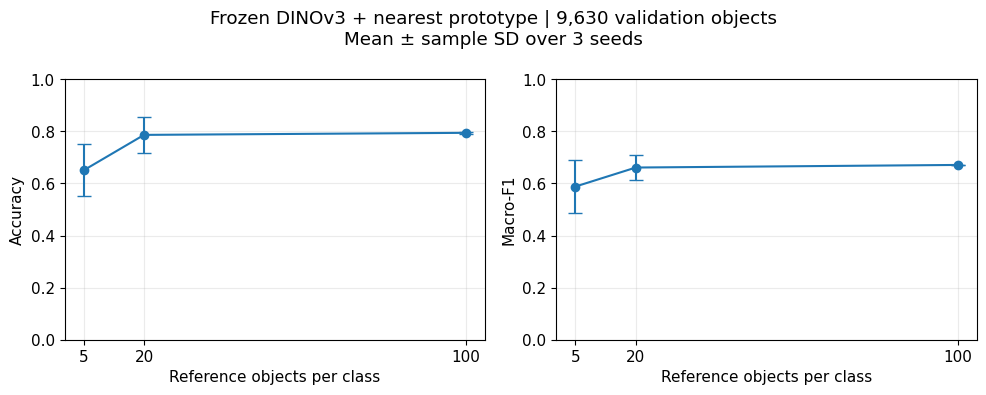

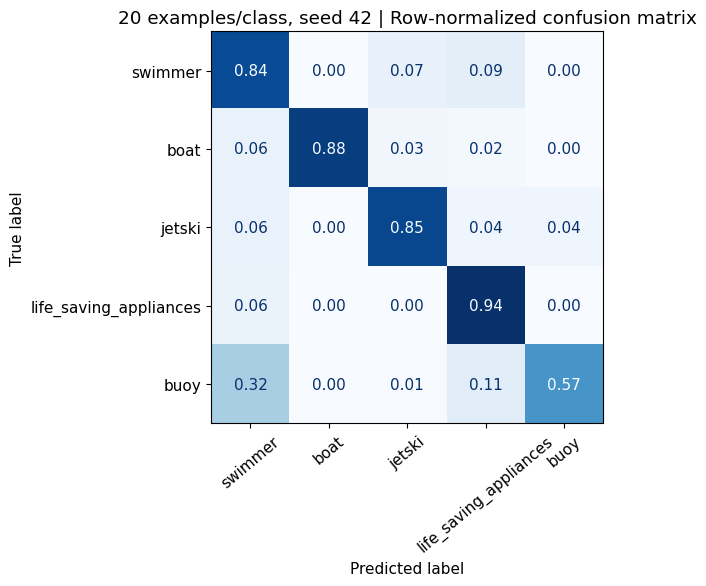

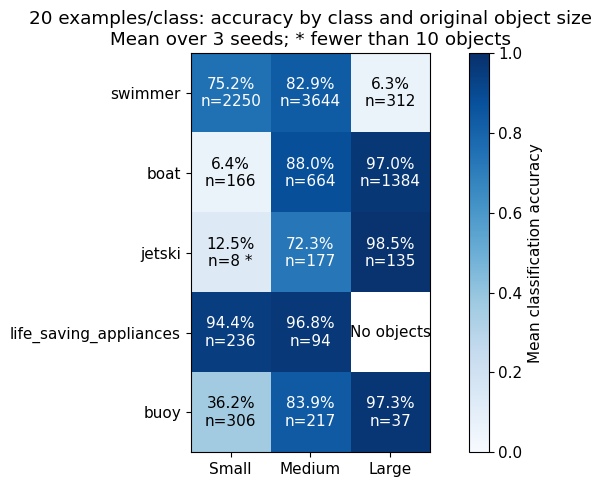

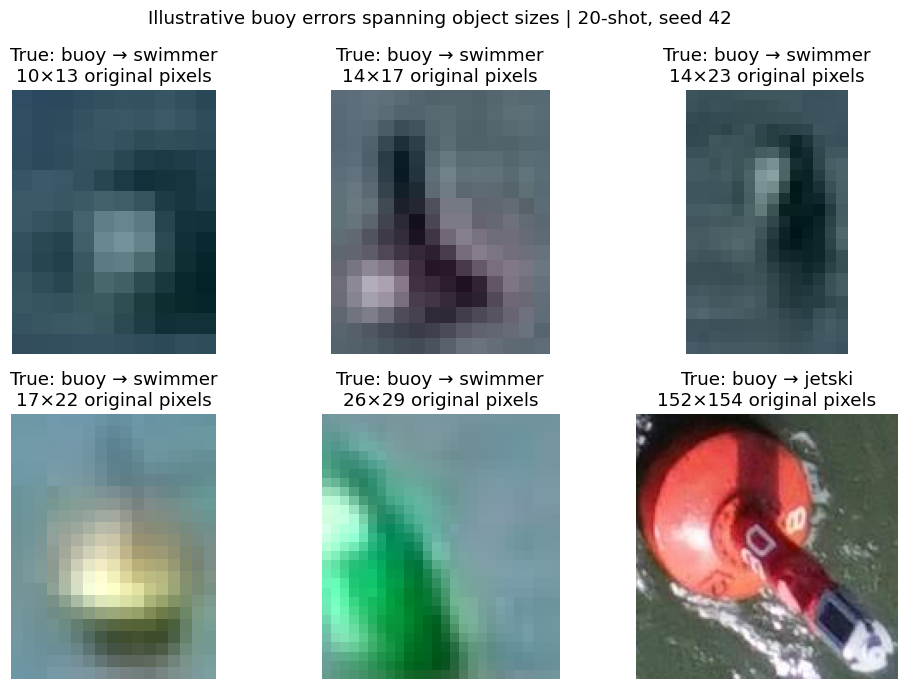

FINISHED. Download: /kaggle/working/classification_full_results.zip
Validation labels were used for evaluation and error analysis, not prototype construction.
This is an exploratory validation experiment, not a held-out test or detection benchmark.


In [5]:
plt.rcParams.update({'font.size': 11})
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, label in zip(axes, ['accuracy', 'macro_f1'], ['Accuracy', 'Macro-F1']):
    ax.errorbar(summary.shots, summary[f'{metric}_mean'], yerr=summary[f'{metric}_std'], marker='o', capsize=5)
    ax.set(xlabel='Reference objects per class', ylabel=label, xticks=SHOTS, ylim=(0, 1))
    ax.grid(alpha=.25)
fig.suptitle(f'Frozen DINOv3 + nearest prototype | {len(y):,} validation objects\nMean ± sample SD over 3 seeds')
fig.tight_layout()
fig.savefig(OUT/'01_shots_comparison.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y, primary_predictions, labels=CLASS_IDS, display_labels=CLASS_NAMES,
    normalize='true', values_format='.2f', xticks_rotation=40, cmap='Blues', ax=ax, colorbar=False)
ax.set_title('20 examples/class, seed 42 | Row-normalized confusion matrix')
fig.tight_layout()
fig.savefig(OUT/'02_confusion_20shot_seed42.png', dpi=180)
plt.show()

# Mean class-conditional accuracy across the three seeds; show sample counts.
subset = class_size_df.query('shots == 20')
matrix = subset.pivot_table(index='class_name', columns='size', values='accuracy').reindex(index=CLASS_NAMES, columns=size_names)
counts = subset.pivot_table(index='class_name', columns='size', values='count', aggfunc='first').reindex(index=CLASS_NAMES, columns=size_names)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(matrix.to_numpy(), vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(3), size_names)
ax.set_yticks(range(5), CLASS_NAMES)
for i in range(5):
    for j in range(3):
        value, n = matrix.iloc[i,j], counts.iloc[i,j]
        text = 'No objects' if pd.isna(value) else f'{value:.1%}\nn={int(n)}' + (' *' if n < 10 else '')
        ax.text(j, i, text, ha='center', va='center', color='white' if pd.notna(value) and value > .6 else 'black')
fig.colorbar(im, ax=ax, label='Mean classification accuracy')
ax.set_title('20 examples/class: accuracy by class and original object size\nMean over 3 seeds; * fewer than 10 objects')
fig.tight_layout()
fig.savefig(OUT/'03_class_by_size.png', dpi=180)
plt.show()

# Illustrative errors from the predefined primary run; not worst-score selection.
errors = val_table.copy()
errors['prediction'] = primary_predictions
errors = errors[errors.category_id != errors.prediction]
buoy_errors = errors.query('category_id == 5').sort_values('area')
if len(buoy_errors):
    n = min(6, len(buoy_errors))
    chosen = buoy_errors.iloc[np.linspace(0, len(buoy_errors)-1, n, dtype=int)]
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, chosen.itertuples()):
        with Image.open(root/'images/val'/row.file_name) as im:
            crop = im.convert('RGB').crop((row.left,row.top,row.right,row.bottom))
        ax.imshow(crop)
        ax.set_title(f'True: buoy → {name_map[row.prediction]}\n{row.width:g}×{row.height:g} original pixels')
        crop.close()
    fig.suptitle('Illustrative buoy errors spanning object sizes | 20-shot, seed 42')
    fig.tight_layout()
    fig.savefig(OUT/'04_buoy_errors.png', dpi=180)
    plt.show()

summary.to_json(OUT/'summary.json', orient='records', indent=2)
archive = Path('/kaggle/working/classification_full_results.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for path in OUT.rglob('*'):
        if path.is_file():
            z.write(path, path.relative_to(OUT))
print('FINISHED. Download:', archive)
print('Validation labels were used for evaluation and error analysis, not prototype construction.')
print('This is an exploratory validation experiment, not a held-out test or detection benchmark.')
